# INSY 684 — Predictive Maintenance
## Parts 2 & 3: Data Preparation and Model Development
**Business problem:** identify machines at risk of failure from operating measurements so maintenance teams can prioritize inspection. The target is `Machine failure` (1 = failure, 0 = normal). This is a classification demonstration on synthetic data, not a validated advance-warning system.

The supplied CSV contains 10,000 observations and 339 failures (3.39%). Because failures are rare, use average precision (PR-AUC summary) for model selection, alongside F1, recall, precision, accuracy and ROC-AUC. Random stratified splitting is used for this classroom experiment; a production evaluation should use time-based splits if timestamps are available.

Run cells in order. Keep the CSV beside this notebook. For a clean environment, install the dependencies in the next cell. MLflow uses a local SQLite database so the registry persists across sessions.

In [39]:
# Uncomment and run once if packages are missing
#%pip install pandas numpy scikit-learn matplotlib mlflow xgboost

In [40]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, ConfusionMatrixDisplay)
from sklearn.base import clone
from IPython.display import display
import importlib.util
SEED = 42
DATA = Path('ai4i2020.csv')
OUT = Path('artifacts')
OUT.mkdir(exist_ok=True)
TRACKING_AVAILABLE = importlib.util.find_spec('mlflow') is not None
if TRACKING_AVAILABLE:
    import mlflow
    import mlflow.sklearn
    from mlflow.models import infer_signature
    mlflow.set_tracking_uri('sqlite:///' + str(Path('mlflow.db').resolve()))
    mlflow.set_registry_uri(mlflow.get_tracking_uri())
    mlflow.set_experiment('AI4I_predictive_maintenance')
else:
    print('MLflow missing: local training works, but install MLflow and rerun all cells to complete tracking and registration.')

## Part 2 — Data Preparation
### 2.1 Load and inspect the dataset

In [41]:
raw = pd.read_csv(DATA)
print('Shape:', raw.shape)
display(raw.head())
display(raw.isna().sum().rename('missing').to_frame())
print('Exact duplicate rows:', raw.duplicated().sum())
print('Duplicate UDI:', raw['UDI'].duplicated().sum())

Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


,missing
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


Exact duplicate rows: 0
Duplicate UDI: 0


### 2.2 Define features and prevent data leakage
Exclude `UDI` and `Product ID` (identifiers). Exclude `TWF`, `HDF`, `PWF`, `OSF`, `RNF`: these describe failure modes and may disclose the outcome. Keep only measurements and product type that are assumed available at prediction time.

Validated rows: 10000


,count
Machine failure,
0,9661
1,339


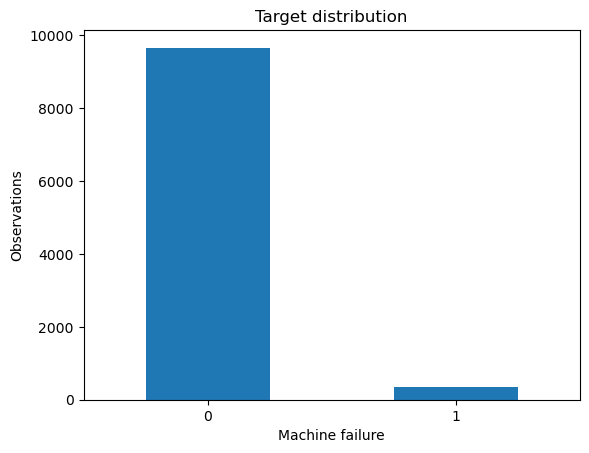

In [42]:
TARGET = 'Machine failure'
CAT = ['Type']
NUM = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
FEATURES = CAT + NUM
assert set(FEATURES + [TARGET, 'UDI']).issubset(raw.columns)
clean = raw.drop_duplicates().copy()
assert clean['UDI'].is_unique, 'Duplicate identifiers require investigation.'
for col in NUM:
    clean[col] = pd.to_numeric(clean[col], errors='raise')
    assert np.isfinite(clean[col].dropna()).all()
clean['Type'] = clean['Type'].str.strip().str.upper()
assert set(clean['Type'].dropna()).issubset({'L','M','H'})
assert clean[TARGET].notna().all() and set(clean[TARGET].unique()) == {0, 1}
for col in NUM[:3]:
    assert (clean[col].dropna() > 0).all()
for col in NUM[3:]:
    assert (clean[col].dropna() >= 0).all()
X = clean[FEATURES].copy()
y = clean[TARGET].astype(int)
print('Validated rows:', len(X))
display(y.value_counts().rename('count').to_frame())
y.value_counts().sort_index().plot.bar(title='Target distribution', rot=0)
plt.xlabel('Machine failure'); plt.ylabel('Observations'); plt.show()

### 2.3 Stratified train/validation/test split (60/20/20)
Fit preprocessing only on training data. Validation selects the model; test is reserved for final evaluation.

In [43]:
X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_hold, y_hold, test_size=0.5, stratify=y_hold, random_state=SEED)
assert not (set(X_train.index) & set(X_val.index) or set(X_train.index) & set(X_test.index) or set(X_val.index) & set(X_test.index))
assert len(X_train)+len(X_val)+len(X_test)==len(X)
splits = {'train': (X_train,y_train), 'validation': (X_val,y_val), 'test': (X_test,y_test)}
for name,(features,labels) in splits.items():
    features.assign(**{TARGET: labels}).to_csv(OUT / f'{name}.csv', index=False)
display(pd.DataFrame([{'split': name,'rows':len(a),'failures':int(t.sum()),'failure_rate':t.mean()} for name,(a,t) in splits.items()]))

,split,rows,failures,failure_rate
0,train,6000,203,0.033833
1,validation,2000,68,0.034000
2,test,2000,68,0.034000


### 2.4 Save reference dataset and input schema
Reference data contains raw training features only, before scaling or encoding, so later drift checks can compare incoming measurements on the same scale.

In [44]:
X_train.to_csv(OUT/'reference.csv', index=False)
schema = {'features': [{'name': col, 'dtype': str(X[col].dtype), 'kind': 'categorical' if col in CAT else 'numeric'} for col in FEATURES],
          'target': {'name': TARGET, 'values': [0,1]}, 'allowed_categories': {'Type':['L','M','H']},
          'missing_policy': 'median for numeric, most frequent for categorical', 'feature_order': FEATURES}
(OUT/'schema.json').write_text(json.dumps(schema, indent=2))
assert list(pd.read_csv(OUT/'reference.csv').columns) == FEATURES
print('Saved train, validation, test, reference and schema files.')

Saved train, validation, test, reference and schema files.


### 2.5 Build reusable preprocessing
Numeric features: median imputation and standardization. Categorical features: most-frequent imputation and one-hot encoding. Unknown categories are ignored by the encoder; upstream schema validation can flag unexpected categories.

In [45]:
numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([('numeric', numeric_pipeline, NUM), ('categorical', categorical_pipeline, CAT)])
# Do not fit here: each model pipeline fits its own preprocessing using training data only.

## Part 3 — Model Development & Experiment Tracking
### 3.1 Define baseline and candidate models
Compare a majority-class baseline, balanced logistic regression, and two random forest configurations. Optional XGBoost is included when installed. The decision threshold is 0.5 for all models; a production threshold should be calibrated against maintenance costs.

In [46]:
models = {
    'baseline': DummyClassifier(strategy='most_frequent'),
    'logistic_balanced': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED),
    'rf_depth_5': RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=SEED, n_jobs=2),
    'rf_depth_12': RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=SEED, n_jobs=2)
}
if importlib.util.find_spec('xgboost'):
    from xgboost import XGBClassifier
    # Original XGBoost
    models['xgboost'] = XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        eval_metric='logloss',
        random_state=SEED,
        n_jobs=2
    )


    # XGBoost with medium positive class weight
    models['xgboost_weight_15'] = XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        scale_pos_weight=15,
        eval_metric='logloss',
        random_state=SEED,
        n_jobs=2
    )

     # XGBoost with low positive class weight
    models['xgboost_weight_5'] = XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        scale_pos_weight=5,
        eval_metric='logloss',
        random_state=SEED,
        n_jobs=2
        )
    # XGBoost with lowest positive class weight
    models['xgboost_weight_3'] = XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        scale_pos_weight=3,
        eval_metric='logloss',
        random_state=SEED,
        n_jobs=2
        )

    models['xgboost_weight_2'] = XGBClassifier(
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            scale_pos_weight=2,
            eval_metric='logloss',
            random_state=SEED,
            n_jobs=2
            )
    

def evaluate(pipeline, features, labels):
    scores = pipeline.predict_proba(features)[:,1]
    predictions = pipeline.predict(features)
    return {'accuracy': accuracy_score(labels,predictions), 'precision': precision_score(labels,predictions,zero_division=0),
            'recall': recall_score(labels,predictions,zero_division=0), 'f1': f1_score(labels,predictions,zero_division=0),
            'roc_auc': roc_auc_score(labels,scores), 'average_precision': average_precision_score(labels,scores)}

### 3.2 Train and log experiments
Each MLflow run records model parameters, split seed, validation metrics and the fitted pipeline. The pipeline includes both preprocessing and classifier, ensuring consistent inference.

In [47]:
from contextlib import nullcontext

results = []
fitted = {}

for name, model in models.items():
    with (
        mlflow.start_run(run_name=name)
        if TRACKING_AVAILABLE
        else nullcontext()
    ) as run:
        pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", clone(model)),
        ])

        pipeline.fit(X_train, y_train)
        metrics = evaluate(pipeline, X_val, y_val)

        if TRACKING_AVAILABLE:
            mlflow.log_params({
                "model_name": name,
                "seed": SEED,
                **model.get_params(),
            })
            mlflow.log_metrics({
                f"val_{key}": value
                for key, value in metrics.items()
            })

            mlflow_X_train = X_train.astype({column: "float64" for column in NUM})
            mlflow.sklearn.log_model(
                pipeline,
                name="pipeline",
                input_example=mlflow_X_train.head(5),
                signature=infer_signature(
                    mlflow_X_train,
                    pipeline.predict(mlflow_X_train),
                ),
                serialization_format="cloudpickle",
            )

        fitted[name] = pipeline
        results.append({"model": name, **metrics})

results = (
    pd.DataFrame(results)
    .sort_values("average_precision", ascending=False)
    .reset_index(drop=True)
)

results.to_csv(OUT / "validation_metrics.csv", index=False)
display(results.round(4))

2026/11/23 22:12:12 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/23 22:12:15 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/23 22:12:17 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mec

,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,xgboost_weight_2,0.9840,0.8600,0.6324,0.7288,0.9676,0.8074
1,xgboost_weight_5,0.9825,0.7538,0.7206,0.7368,0.9669,0.7976
2,xgboost_weight_3,0.9860,0.8448,0.7206,0.7778,0.9722,0.7974
3,xgboost_weight_15,0.9715,0.5545,0.8235,0.6627,0.9621,0.7910
4,xgboost,0.9615,0.4640,0.8529,0.6010,0.9690,0.7565
5,rf_depth_12,0.9745,0.7429,0.3824,0.5049,0.9479,0.6465
6,rf_depth_5,0.9425,0.3444,0.7647,0.4749,0.9423,0.4772
7,logistic_balanced,0.8410,0.1508,0.7941,0.2535,0.8811,0.4072
8,baseline,0.9660,0.0000,0.0000,0.0000,0.5000,0.0340


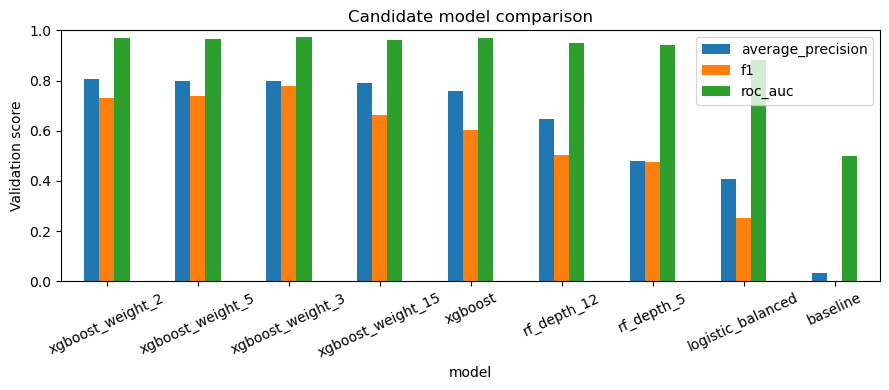

Selected model by validation average precision: xgboost_weight_2


In [48]:
results.set_index('model')[['average_precision','f1','roc_auc']].plot.bar(figsize=(9,4), ylim=(0,1), rot=25)
plt.ylabel('Validation score'); plt.title('Candidate model comparison'); plt.tight_layout(); plt.show()
best_name = results.iloc[0]['model']
print('Selected model by validation average precision:', best_name)

### 3.3 Final evaluation on untouched test data
Refit the selected configuration using training and validation data combined. Evaluate test data once; do not use these metrics to select another model.

,test
accuracy,0.9850
precision,0.8276
recall,0.7059
f1,0.7619
roc_auc,0.9840
average_precision,0.7973


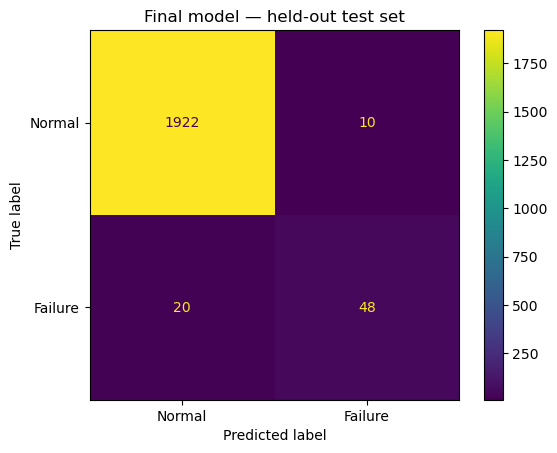

194

In [49]:
X_dev = pd.concat([X_train, X_val]); y_dev = pd.concat([y_train, y_val])
final_pipeline = Pipeline([('preprocessor', clone(preprocessor)), ('model', clone(models[best_name]))])
final_pipeline.fit(X_dev, y_dev)
test_metrics = evaluate(final_pipeline, X_test, y_test)
display(pd.Series(test_metrics, name='test').round(4).to_frame())
ConfusionMatrixDisplay.from_estimator(final_pipeline, X_test, y_test, display_labels=['Normal','Failure'])
plt.title('Final model — held-out test set'); plt.show()
(OUT/'test_metrics.json').write_text(json.dumps(test_metrics, indent=2))

### 3.4 Register the final model and verify inference
Register the entire fitted sklearn Pipeline as one versioned model, not just the classifier. This guarantees that raw feature inputs use the same preprocessing. Keep a local joblib copy as well.

In [50]:
import joblib
joblib.dump(final_pipeline, OUT/'final_pipeline.joblib')
MODEL_NAME = 'AI4I_Predictive_Maintenance'
if TRACKING_AVAILABLE:
    with mlflow.start_run(run_name='final_selected_model') as run:
        mlflow.log_params({'selected_model':best_name,'seed':SEED,**models[best_name].get_params()})
        mlflow.log_metrics({f'test_{key}':value for key,value in test_metrics.items()})
        mlflow.log_artifact(str(OUT/'schema.json'))
        mlflow.log_artifact(str(OUT/'validation_metrics.csv'))
        mlflow_X_dev = X_dev.astype({column: "float64" for column in NUM})
        info = mlflow.sklearn.log_model(final_pipeline, name='pipeline',
            registered_model_name=MODEL_NAME, input_example=mlflow_X_dev.head(5),
            signature=infer_signature(mlflow_X_dev, final_pipeline.predict(mlflow_X_dev)),
            serialization_format='cloudpickle')
    client = mlflow.tracking.MlflowClient()
    versions = client.search_model_versions(f"name = '{MODEL_NAME}'")
    version = max(int(v.version) for v in versions if v.run_id == run.info.run_id)
    model_uri = f'models:/{MODEL_NAME}/{version}'
    loaded = mlflow.sklearn.load_model(model_uri)
    np.testing.assert_array_equal(loaded.predict(X_test.head(10)), final_pipeline.predict(X_test.head(10)))
    print('Registered and verified:', model_uri)
else:
    print('Registry NOT completed. Install mlflow and rerun all cells.')
local_model = joblib.load(OUT/'final_pipeline.joblib')
np.testing.assert_array_equal(local_model.predict(X_test.head(10)), final_pipeline.predict(X_test.head(10)))
print('Local model reload verified.')

2026/11/23 22:12:32 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Registered and verified: models:/AI4I_Predictive_Maintenance/4
Local model reload verified.


Registered model 'AI4I_Predictive_Maintenance' already exists. Creating a new version of this model...
Created version '4' of model 'AI4I_Predictive_Maintenance'.


## Next steps — integration with MLOps
- Run `mlflow server --backend-store-uri sqlite:///mlflow.db --port 5000` from the notebook directory, then open `http://localhost:5000` to view runs and registered models.
- Use `artifacts/reference.csv` and `artifacts/schema.json` for drift monitoring and input validation.
- Move the training logic into Python functions and Prefect tasks for the final orchestrated pipeline. This notebook is for development and experimentation, not a replacement for the required training flow.
- Avoid committing the SQLite database or generated model artifacts to a public repository unless the project requires them; document how to regenerate them.